# Counting objects with LLMs: a well-specified prompt

---
*Introduction to Image Analysis Workshop*

*Stefania Marcotti (stefania.marcotti@crick.ac.uk) and Dave Barry (david.barry@crick.ac.uk)*

*Intro to using LLMs for image analysis*

*CC-BY-SA-4.0 license: creativecommons.org/licenses/by-sa/4.0/*

---


This notebook shows what happens when an LLM is given a well-specified prompt
that describes the image data in detail.

The prompt states the image dimensions and type, what it shows (cell nuclei, a
Hoechst stain), how the objects appear (bright, round, on a dark background,
some touching), and the name of the variable holding the data. Because the
models no longer need to guess, they converge on essentially the same, correct
workflow. Note that the image itself was never sent to the models: a precise
textual description was enough.


## The prompt

The following prompt was given to each model:

> I have a 2D multichannel fluorescence microscopy image of some cells that I need to analyse. The image, in TIF format,
> consists of four channels:
> 1. Nuclei (Hoechst)
> 2. Tubulin
> 3. Actin (Phalloidin)
> 4. YAP/TAZ
> Can you write a Python script to determine this? The script should use the nuclear channel to segment and count the
> cells, using simple grey-level thresholding. The outputs should consist of an overlay of the segmented cells on the 
> original image and a table in markdown format containing the following columns:
> * Input filename (stored in the variable `filename`)
> * Thresholding method used
> * Thresholding value used
> * Number of cells
> * Notes (any additional information that may be useful)
> Keep the code as short and as simple as possible and make extensive use of comments to aid in interpretation.
> The code will go into an existing Jupyter notebook that loads the image into a variable called `img`.


## Import libraries


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi
from skimage import color
from skimage import filters, morphology, segmentation, measure, feature
from skimage import io
from skimage.color import rgb2gray
from skimage.filters import gaussian, threshold_otsu
from skimage.measure import label
from skimage.morphology import opening, disk, remove_small_objects
from skimage.segmentation import watershed

## Open image

To run each model's code, we first load the image. The 4-channel field is made available as `img`, with its path stored in `filename`.


In [2]:
# read the 4-channel .tif file (nuclei, tubulin, actin, YAP/TAZ)
filename = '../../Data/idr0028/003003-10.tif'
img = io.imread(filename)

In [3]:
# print image dimensions
print('Image dimensions:', img.shape)

Image dimensions: (501, 667, 4)


## Model outputs

Each model was asked to write code; the code was then run against the same image. The cells below show exactly what each model returned.


### Claude Haiku 5-5

C:\Users\davej\AppData\Local\Temp\ipykernel_26868\1031897104.py:17: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=min_size)


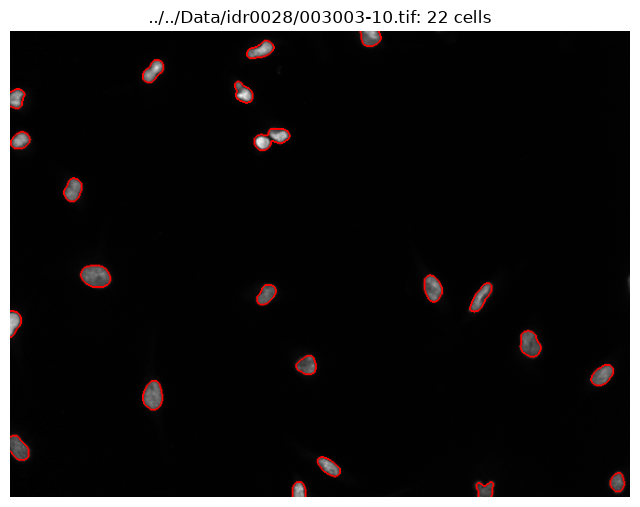

| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---|---|---|---|
| ../../Data/idr0028/003003-10.tif | Otsu (global) | 368.5 | 22 | Gaussian sigma=2; min object size=50 px; median nucleus area=326 px; touching nuclei not split (no watershed) |


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, morphology, segmentation, color

# --- 1. Select the nuclear channel (Hoechst = channel 1) ---
# Channel-first (4, H, W) or channel-last (H, W, 4)? Adjust if needed.
nuc = img[0] if img.shape[0] == 4 else img[..., 0]
nuc = nuc.astype(float)

# --- 2. Smooth to reduce noise, then apply a global Otsu threshold ---
smooth = filters.gaussian(nuc, sigma=2, preserve_range=True)  # sigma ~ nucleus size / 10
thr = filters.threshold_otsu(smooth)                          # automatic grey-level threshold
mask = smooth > thr                                           # binary: nucleus vs background

# --- 3. Clean the mask ---
min_size = 50                                                 # px; removes debris, adjust to nucleus size
mask = morphology.remove_small_objects(mask, min_size=min_size)
mask = morphology.remove_small_holes(mask)                    # fill holes inside nuclei

# --- 4. Label connected blobs: each blob = one nucleus ---
labels = measure.label(mask)
n_cells = labels.max()                                        # number of labelled objects

# --- 5. Overlay: red outlines of segmented nuclei on the nuclear image ---
disp = (nuc - nuc.min()) / (nuc.max() - nuc.min())            # rescale to 0-1 for display
overlay = color.gray2rgb(disp)
overlay[segmentation.find_boundaries(labels)] = [1, 0, 0]     # paint boundaries red

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(overlay)
ax.set_title(f'{filename}: {n_cells} cells')
ax.axis('off')
plt.savefig(filename.rsplit('.', 1)[0] + '_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 6. Results table in Markdown ---
areas = [r.area for r in measure.regionprops(labels)]        # area of each nucleus (px)
median_area = np.median(areas) if areas else 0
notes = (f"Gaussian sigma=2; min object size={min_size} px; "
         f"median nucleus area={median_area:.0f} px; "
         "touching nuclei not split (no watershed)")

table = f"""| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---|---|---|---|
| {filename} | Otsu (global) | {thr:.1f} | {n_cells} | {notes} |"""
print(table)


### Claude Sonnet 5-5

C:\Users\davej\AppData\Local\Temp\ipykernel_26868\3557956622.py:21: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=min_size)  # remove debris/noise
C:\Users\davej\AppData\Local\Temp\ipykernel_26868\3557956622.py:22: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller one

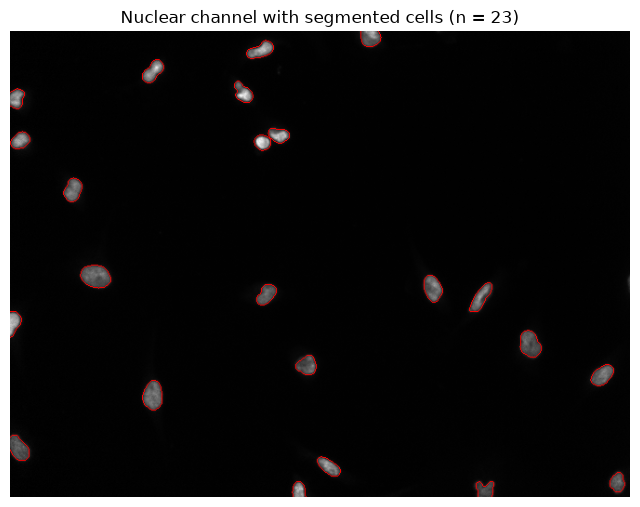

| Filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---|---|---|---|
| ../../Data/idr0028/003003-10.tif | Otsu (global) | 401.33 | 23 | Gaussian blur (sigma=1) applied before thresholding; objects < 30 px removed; no splitting of touching nuclei, so clusters count as one cell and the count may be underestimated; edge-touching nuclei are included |

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, morphology, segmentation, exposure
from IPython.display import display, Markdown

# --- 1. Select the nuclear channel (channel 1, Hoechst) ---
# Make sure channels come first: (4, H, W). If they come last (H, W, 4), move them.
im = np.moveaxis(img, -1, 0) if img.shape[-1] == 4 else img
nuc = im[0]

# --- 2. Pre-process: light Gaussian blur to suppress noise ---
# preserve_range keeps the original grey-level units, so the threshold value is interpretable
smooth = filters.gaussian(nuc, sigma=1, preserve_range=True)

# --- 3. Simple global grey-level threshold (Otsu's method) ---
thresh = filters.threshold_otsu(smooth)
mask = smooth > thresh

# --- 4. Clean up the binary mask ---
min_size = 30                                        # smallest object kept (pixels)
mask = morphology.remove_small_objects(mask, min_size=min_size)  # remove debris/noise
mask = morphology.remove_small_holes(mask, min_size)             # fill small holes in nuclei

# --- 5. Label connected components: each one is counted as one cell ---
labels = measure.label(mask)
n_cells = labels.max()

# --- 6. Overlay the segmentation outlines on the original (nuclear) image ---
disp = exposure.rescale_intensity(nuc.astype(float), out_range=(0, 1))  # contrast stretch for display
overlay = segmentation.mark_boundaries(disp, labels, color=(1, 0, 0))   # red outlines
plt.figure(figsize=(8, 8))
plt.imshow(overlay)
plt.title(f"Nuclear channel with segmented cells (n = {n_cells})")
plt.axis("off")
plt.show()

# --- 7. Results table in markdown format ---
notes = (f"Gaussian blur (sigma=1) applied before thresholding; objects < {min_size} px removed; "
         "no splitting of touching nuclei, so clusters count as one cell and the count may be underestimated; "
         "edge-touching nuclei are included")
table = (
    "| Filename | Thresholding method | Thresholding value | Number of cells | Notes |\n"
    "|---|---|---|---|---|\n"
    f"| {filename} | Otsu (global) | {thresh:.2f} | {n_cells} | {notes} |"
)
display(Markdown(table))


### Claude Opus 5-5

C:\Users\davej\AppData\Local\Temp\ipykernel_26868\3363909851.py:32: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, MIN_AREA) # remove small debris


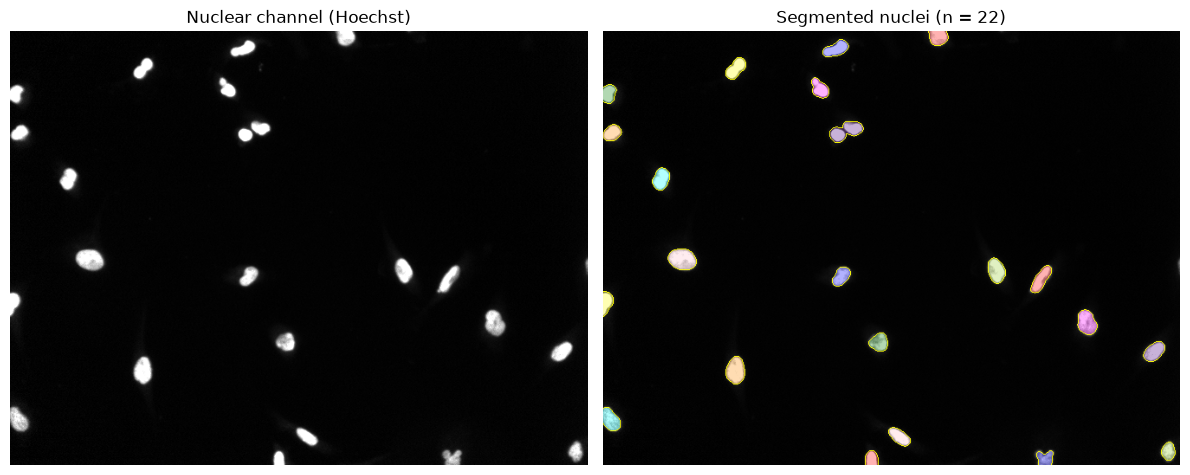

| Filename | Threshold method | Threshold value | Number of cells | Notes |
|---|---|---|---|---|
| ../../Data/idr0028/003003-10.tif | Otsu (global) | 368.51 | 22 | Image shape (501, 667, 4); Gaussian sigma=2; min area=50 px; 6 nuclei touch the border; touching nuclei are not split, so the count may be an underestimate |

| Filename | Threshold method | Threshold value | Number of cells | Notes |
|---|---|---|---|---|
| ../../Data/idr0028/003003-10.tif | Otsu (global) | 368.51 | 22 | Image shape (501, 667, 4); Gaussian sigma=2; min area=50 px; 6 nuclei touch the border; touching nuclei are not split, so the count may be an underestimate |


In [6]:
# ============================================================
# Nuclear segmentation & cell counting by grey-level thresholding
# Assumes `img` (4-channel image) and `filename` already exist
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, measure, segmentation, color, exposure
from IPython.display import Markdown, display

# --- Parameters (adjust to suit your image resolution) ---
SIGMA = 2          # Gaussian blur radius (pixels) to suppress noise before thresholding
MIN_AREA = 50      # Objects smaller than this (pixels) are treated as debris and removed

# --- 1. Extract the nuclear channel (channel 1 = Hoechst) ---
# The channel axis is assumed to be the smallest dimension (size 4).
# This works for both (C, Y, X) and (Y, X, C) layouts.
ch_axis = int(np.argmin(img.shape))
nuc = np.take(img, 0, axis=ch_axis).astype(float)

# --- 2. Smooth the image to reduce noise ---
nuc_smooth = filters.gaussian(nuc, sigma=SIGMA, preserve_range=True)

# --- 3. Global grey-level threshold using Otsu's method ---
# Otsu picks the value that best separates foreground (nuclei)
# from background, based on the intensity histogram.
thresh = filters.threshold_otsu(nuc_smooth)
mask = nuc_smooth > thresh

# --- 4. Clean up the binary mask ---
mask = ndi.binary_fill_holes(mask)                     # fill holes inside nuclei
mask = morphology.remove_small_objects(mask, MIN_AREA) # remove small debris

# --- 5. Label connected objects (each object = one nucleus/cell) ---
labels = measure.label(mask)
n_cells = labels.max()

# Count how many nuclei touch the image edge (these may be partial cells)
n_border = n_cells - len(np.unique(segmentation.clear_border(labels))) + 1

# --- 6. Create the overlay ---
# Contrast-stretch the nuclear channel for display (1st-99th percentile)
p1, p99 = np.percentile(nuc, (1, 99))
nuc_disp = exposure.rescale_intensity(nuc, in_range=(p1, p99), out_range=(0, 1))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(nuc_disp, cmap='gray')
ax[0].set_title('Nuclear channel (Hoechst)')

# Coloured labels blended onto the image, with outlines drawn in yellow
overlay = color.label2rgb(labels, image=nuc_disp, alpha=0.3, bg_label=0)
overlay = segmentation.mark_boundaries(overlay, labels, color=(1, 1, 0))
ax[1].imshow(overlay)
ax[1].set_title(f'Segmented nuclei (n = {n_cells})')

for a in ax:
    a.axis('off')
plt.tight_layout()
plt.savefig('segmentation_overlay.png', dpi=150)  # also save overlay to disk
plt.show()

# --- 7. Summary table in markdown format ---
notes = (f"Image shape {img.shape}; Gaussian sigma={SIGMA}; min area={MIN_AREA} px; "
         f"{n_border} nuclei touch the border; touching nuclei are not split, "
         f"so the count may be an underestimate")

table = (
    "| Filename | Threshold method | Threshold value | Number of cells | Notes |\n"
    "|---|---|---|---|---|\n"
    f"| {filename} | Otsu (global) | {thresh:.2f} | {n_cells} | {notes} |"
)
display(Markdown(table))  # rendered table in the notebook
print(table)              # raw markdown text for copy/paste


### Mistral Small 4

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..3935].


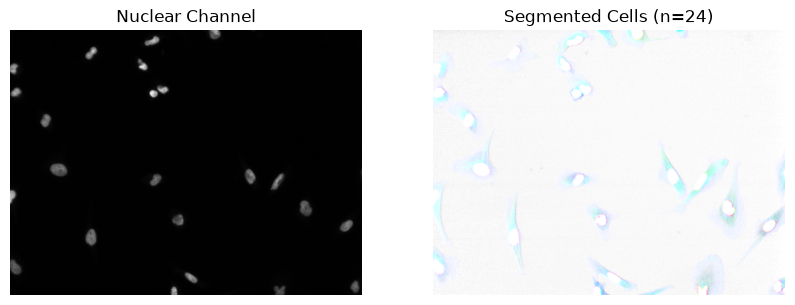

Input filename,Thresholding method used,Thresholding value used,Number of cells,Notes
../../Data/idr0028/003003-10.tif,Otsu,419,24,Simple Otsu thresholding on nuclear channel


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure
import pandas as pd

# Assuming 'img' is already loaded in your notebook as a numpy array
# with shape (height, width, 4) where channels are [Nuclei, Tubulin, Actin, YAP/TAZ]

# Extract the nuclear channel (channel 0)
nuclear_channel = img[:, :, 0]

# Simple thresholding using Otsu's method (automatic threshold selection)
threshold_value = filters.threshold_otsu(nuclear_channel)
binary_mask = nuclear_channel > threshold_value

# Label connected regions (cells)
labeled_cells = measure.label(binary_mask)
num_cells = np.max(labeled_cells)

# Create an overlay image (original RGB with segmented nuclei in red)
overlay = img.copy()
overlay[labeled_cells > 0] = [255, 0, 0, 0]  # Set segmented cells to red (RGBA)

# Display the overlay
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(nuclear_channel, cmap='gray')
plt.title('Nuclear Channel')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title(f'Segmented Cells (n={num_cells})')
plt.axis('off')
plt.show()

# Create results table
results = pd.DataFrame({
    'Input filename': [filename],
    'Thresholding method used': ['Otsu'],
    'Thresholding value used': [threshold_value],
    'Number of cells': [num_cells],
    'Notes': ['Simple Otsu thresholding on nuclear channel']
})

# Display table in markdown format
display(results.style.hide(axis="index"))


### Mistral Large 4

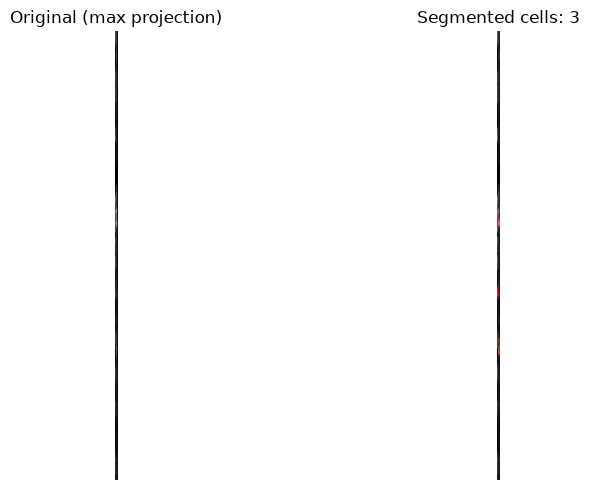

| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---|---|---|---|
| ../../Data/idr0028/003003-10.tif | Otsu | 585.41 | 3 | Hoechst channel; connected components; no size filter |


In [8]:
# ============================================================
#  Cell counting from a 4‑channel fluorescence TIF
#  Channel order: 0=Nuclei(Hoechst), 1=Tubulin, 2=Actin, 3=YAP/TAZ
#  Pre‑existing variables: img (numpy array), filename (str)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, segmentation, color

# --- 1. Grab the nuclei channel ---------------------------------
# If img.shape is (H, W, 4) instead of (4, H, W), uncomment:
# img = np.moveaxis(img, -1, 0)
nuclei = img[0].astype(float)          # channel 0 = Hoechst

# --- 2. Simple grey‑level thresholding (Otsu) -------------------
thresh_val = filters.threshold_otsu(nuclei)   # automatic global threshold
binary = nuclei > thresh_val                   # boolean mask of nuclei

# --- 3. Count cells as connected components ----------------------
labels = measure.label(binary)         # each nucleus gets a unique integer ID
num_cells = labels.max()               # label 0 is background → max ID = cell count

# --- 4. Overlay segmentation on the original image --------------
# Build a quick grayscale background from the max‑projection of all 4 channels
bg = img.max(axis=0)
bg = (bg - bg.min()) / (bg.max() - bg.min() + 1e-8)   # normalise to 0‑1

rgb = color.gray2rgb(bg)               # convert to RGB so we can colour the outlines
edges = segmentation.find_boundaries(labels, mode='outer')
rgb[edges] = [1, 0, 0]                 # draw cell borders in red

# Display original and overlay side‑by‑side
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(bg, cmap='gray'); ax[0].set_title('Original (max projection)'); ax[0].axis('off')
ax[1].imshow(rgb);         ax[1].set_title(f'Segmented cells: {num_cells}'); ax[1].axis('off')
plt.tight_layout()
plt.show()

# --- 5. Markdown results table -----------------------------------
print("| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |")
print("|---|---|---|---|---|")
print(f"| {filename} | Otsu | {thresh_val:.2f} | {num_cells} "
      f"| Hoechst channel; connected components; no size filter |")


### Mistral Codestral

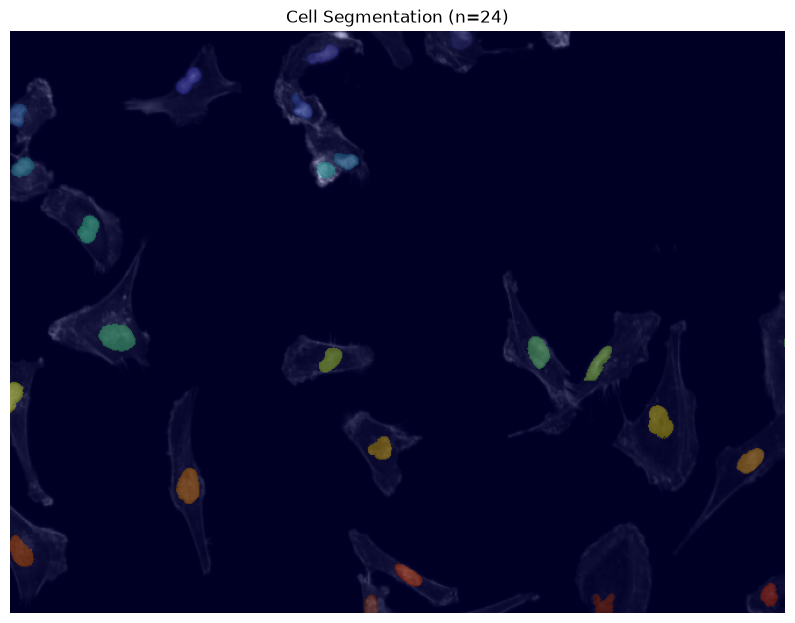


| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|----------------|--------------------|--------------------|-----------------|-------|
| ../../Data/idr0028/003003-10.tif     | Otsu's threshold   | 419.00 | 24 | Simple grey-level thresholding on nuclear channel |



In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.filters import threshold_otsu

# Assuming img is a 3D numpy array with shape (height, width, channels)
# Channel order: 0=Nuclei, 1=Tubulin, 2=Actin, 3=YAP/TAZ

# Extract the nuclear channel (Hoechst)
nuclei_channel = img[:, :, 0]

# Apply Otsu's thresholding to segment nuclei
threshold_value = threshold_otsu(nuclei_channel)
binary_mask = nuclei_channel > threshold_value

# Label connected regions (cells)
labeled_cells = label(binary_mask)
num_cells = labeled_cells.max()  # Number of unique regions (cells)

# Create overlay visualization
plt.figure(figsize=(10, 8))
plt.imshow(img.max(axis=2), cmap='gray')  # Show maximum projection of all channels
plt.imshow(labeled_cells, cmap='jet', alpha=0.3)  # Overlay cell labels
plt.title(f'Cell Segmentation (n={num_cells})')
plt.axis('off')
plt.show()

# Generate markdown table output
markdown_output = f"""
| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|----------------|--------------------|--------------------|-----------------|-------|
| {filename}     | Otsu's threshold   | {threshold_value:.2f} | {num_cells} | Simple grey-level thresholding on nuclear channel |
"""

print(markdown_output)


### Deepseek Flash

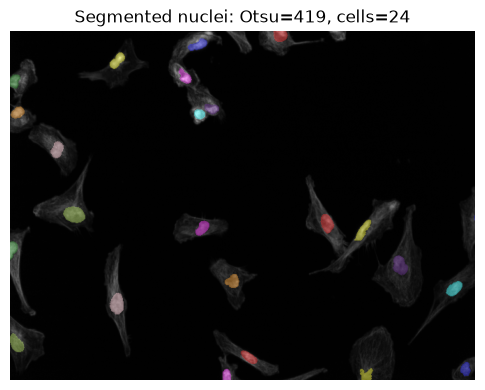


| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---:|---:|---:|---|
| `../../Data/idr0028/003003-10.tif` | Otsu (global grey-level) | 419 | 24 | Hoechst channel thresholded by Otsu; connected-component count; touching nuclei are not split; overlay uses actin/tubulin/Hoechst RGB. |


In [10]:
# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from skimage import filters, measure, color

# --- Ensure the 4-channel image is in (Y, X, C) order ---
if img.ndim == 3 and img.shape[-1] == 4:       # already YXC
    ch = img
elif img.ndim == 3 and img.shape[0] == 4:      # CYX -> YXC
    ch = np.moveaxis(img, 0, -1)
else:
    raise ValueError("Expected a 3D image with 4 channels (YXC or CYX).")

# --- Nuclear channel: Hoechst is channel 0 ---
nuc = ch[..., 0]

# --- Simple grey-level thresholding using Otsu's method ---
thr = filters.threshold_otsu(nuc)              # automatic threshold value
mask = nuc > thr                               # binary nuclear mask

# --- Count connected nuclear regions as cells ---
labels = measure.label(mask)                   # label connected components
n_cells = labels.max()                         # number of labelled objects

# --- Make an RGB composite for the overlay background ---
def norm(x):                                   # scale each channel to 0-1 for display
    x = x.astype(float)
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# RGB = actin (red), tubulin (green), nuclei (blue); YAP/TAZ not shown
rgb = np.dstack([norm(ch[..., 2]), norm(ch[..., 1]), norm(ch[..., 0])])

# --- Overlay segmented nuclei on the RGB composite ---
overlay = color.label2rgb(labels, image=rgb, bg_label=0, alpha=0.35)

# --- Display overlay ---
plt.figure(figsize=(6, 6))
plt.imshow(overlay)
plt.title(f"Segmented nuclei: Otsu={thr:.3g}, cells={n_cells}")
plt.axis("off")
plt.show()

# --- Markdown results table ---
notes = ("Hoechst channel thresholded by Otsu; connected-component count; "
         "touching nuclei are not split; overlay uses actin/tubulin/Hoechst RGB.")
display(Markdown(f"""
| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
|---|---:|---:|---:|---|
| `{filename}` | Otsu (global grey-level) | {thr:.3g} | {n_cells} | {notes} |
"""))


### Deepseek V4 Pro

C:\Users\davej\AppData\Local\Temp\ipykernel_26868\2092059381.py:29: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=64)
C:\Users\davej\AppData\Local\Temp\ipykernel_26868\2092059381.py:30: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove

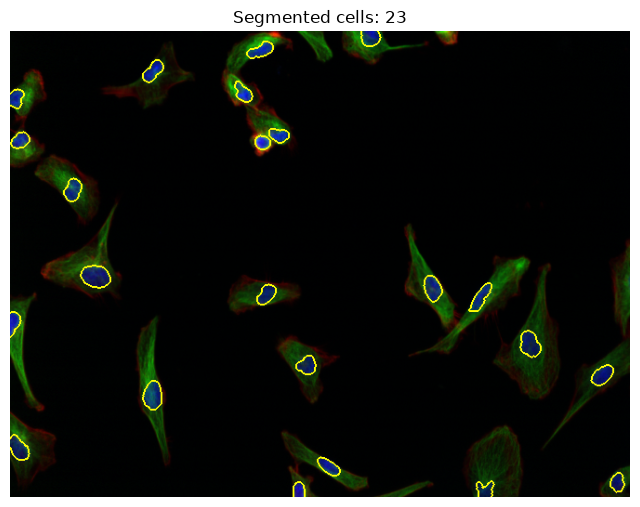

| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |
| --- | --- | --- | --- | --- |
| ../../Data/idr0028/003003-10.tif | Otsu (global grey-level) | 419.00 | 23 | Nuclear channel (ch 0); touching nuclei are not split; YAP/TAZ not used |


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, morphology
from skimage.segmentation import mark_boundaries

# If filename is not already defined, set a fallback.
try:
    filename
except NameError:
    filename = "image.tif"

# --- Identify channel layout ---
# Assume: channel 0 = nuclei, 1 = tubulin, 2 = actin, 3 = YAP/TAZ.
# Handle both (C, H, W) and (H, W, C) array layouts.
if img.ndim == 3 and img.shape[0] <= 4:
    nuclear = img[0]
    tubulin = img[1]
    actin = img[2]
else:
    nuclear = img[..., 0]
    tubulin = img[..., 1]
    actin = img[..., 2]

# --- Simple global grey-level thresholding using Otsu ---
thresh = filters.threshold_otsu(nuclear)
mask = nuclear > thresh

# --- Clean up binary mask ---
mask = morphology.remove_small_objects(mask, min_size=64)
mask = morphology.remove_small_holes(mask, area_threshold=64)

# --- Count cells/nuclei as connected components ---
labels = measure.label(mask, connectivity=2)
n_cells = labels.max()

# --- Build RGB composite: nuclei=blue, tubulin=green, actin=red ---
def normalize(ch):
    ch = ch.astype(np.float32)
    ch -= ch.min()
    ch /= ch.max() + 1e-8
    return ch

composite = np.stack([normalize(actin),
                      normalize(tubulin),
                      normalize(nuclear)], axis=-1)

# --- Overlay segmentation boundaries on the composite ---
overlay = mark_boundaries(composite, labels, color=(1, 1, 0), mode='thick')

plt.figure(figsize=(8, 8))
plt.imshow(overlay)
plt.title(f"Segmented cells: {n_cells}")
plt.axis("off")
plt.show()

# --- Markdown table ---
print("| Input filename | Thresholding method | Thresholding value | Number of cells | Notes |")
print("| --- | --- | --- | --- | --- |")
print(f"| {filename} | Otsu (global grey-level) | {thresh:.2f} | {n_cells} | Nuclear channel (ch 0); touching nuclei are not split; YAP/TAZ not used |")


## Results

| Model | Count |
| --- | --- |
| Claude Haiku 5-5 | 22 |
| Claude Sonnet 5-5 | 23 |
| Claude Opus 5-5 | 22 |
| Mistral Small 4 | - |
| Mistral Large 4 | 3 |
| Mistral Codestral | 24 |
| Deepseek Flash | 24 |
| Deepseek V4 Pro | 23 |


## Conclusion

A well-specified prompt removes the guesswork, and the models converge on the
same approach and the same answer. The image itself did not need to be sent,
because a precise description of the data was sufficient.

Two things still hold. First, there is no single correct count: the answer
depends on how you define an object, and two careful human annotators will
usually disagree too. Second, the models still perform no quality control of
their own, so domain expertise still matters. But a good prompt gets you much
further.
